DiD: Neuenburg vs. Aargau, St. Gallen (erstes volles Jahr 2018)

Modell  β3 (log)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.531        0.138 0.00012 0.397        -41.2


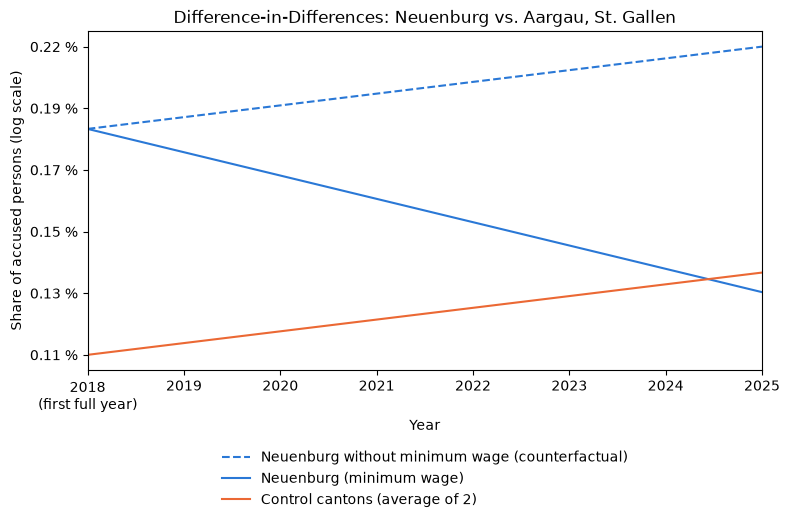

In [1]:
### Neuenburg => Minimum wage in august 2017

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen
# =============================================================
MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTONE   = ["Aargau", "St. Gallen"]
ERSTES_VOLLES_JAHR = 2018          # Einführung August 2017 → erstes volles Jahr 2018

# =============================================================
# 2. Daten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)
d["After"] = (d["Year"] >= ERSTES_VOLLES_JAHR).astype(int)

# =============================================================
# 3. Regression (HC1, weil nur wenige Kantone)
# =============================================================
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"],
    "β3 (log)": [mA.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],
    "R²": [mA.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (log)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)} (erstes volles Jahr {ERSTES_VOLLES_JAHR})\n")
print(ergebnis.round({"β3 (log)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik (Schätzung in log, Achse in %)
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]
jahre = list(range(ERSTES_VOLLES_JAHR, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

# log-Werte zurück in Prozent umrechnen
treat      = np.exp([b0 + b1, b0 + b1 + b2 + b3]) * 100
kontrolle  = np.exp([b0,      b0 + b2]) * 100
kontrafakt = np.exp([b0 + b1, b0 + b1 + b2]) * 100

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

# log-skalierte Achse, beschriftet in %
plt.yscale("log")
werte = np.concatenate([treat, kontrolle, kontrafakt])
ticks = np.geomspace(werte.min(), werte.max(), 6)
plt.yticks(ticks, [f"{t:.2f} %" for t in ticks])
plt.minorticks_off()

beschriftung = [f"{ERSTES_VOLLES_JAHR}\n(first full year)"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("Share of accused persons (log scale)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

    Year  treat  kontrolle  differenz  effekt  effekt_prozent
0   2010 -6.086     -7.178      1.092  -0.011          -1.142
1   2011 -6.760     -7.481      0.721  -0.382         -31.768
2   2012 -6.367     -7.383      1.016  -0.088          -8.384
3   2013 -6.079     -7.267      1.187   0.084           8.793
4   2014 -6.460     -7.092      0.633  -0.471         -37.540
5   2015 -6.223     -7.200      0.978  -0.126         -11.804
6   2016 -6.199     -7.302      1.103   0.000           0.000
7   2017 -6.273     -7.284      1.011  -0.092          -8.789
8   2018 -6.488     -6.981      0.493  -0.610         -45.673
9   2019 -6.392     -7.146      0.754  -0.349         -29.451
10  2020 -6.277     -7.130      0.853  -0.250         -22.137
11  2021 -6.901     -7.146      0.246  -0.858         -57.583
12  2022 -6.593     -6.936      0.343  -0.760         -53.230
13  2023 -6.742     -7.171      0.429  -0.674         -49.040
14  2024 -6.870     -6.843     -0.027  -1.130         -67.708
15  2025

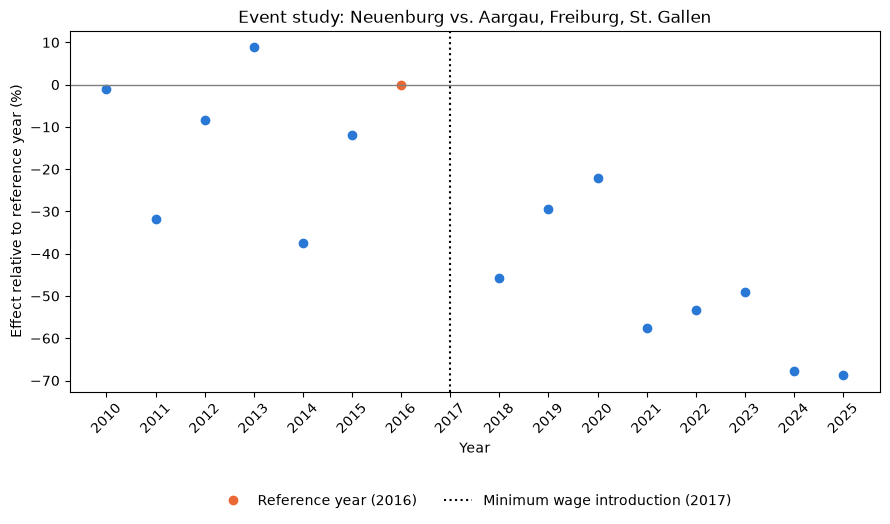

In [ ]:
### Event study Neuenburg => Minimum wage in august 2017

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Neuenburg"
KONTROLL_KANTONE   = ["Aargau", "St. Gallen"]
EINFUEHRUNG        = 2017          # Jahr der Einführung (Neuenburg: August 2017)

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz

# Schritt 5: log-Differenz in % umrechnen
es["effekt_prozent"] = (np.exp(es["effekt"]) - 1) * 100
print(es.round(3))

# Schritt 6: plotten
punkte         = es[(es["Year"] != EINFUEHRUNG) & (es["Year"] != EINFUEHRUNG - 1)]
referenz_punkt = es[es["Year"] == EINFUEHRUNG - 1]

plt.figure(figsize=(9, 5.5))
plt.plot(punkte["Year"], punkte["effekt_prozent"], "o", color="#2a78d6")
plt.plot(referenz_punkt["Year"], referenz_punkt["effekt_prozent"], "o", color="#eb6834",
         label=f"Reference year ({EINFUEHRUNG - 1})")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(EINFUEHRUNG, color="black", linestyle=":",
            label=f"Minimum wage introduction ({EINFUEHRUNG})")
plt.xticks(es["Year"], rotation=45)
plt.xlabel("Year")
plt.ylabel("Effect relative to reference year (%)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, ncol=2)
plt.tight_layout()
plt.show()

DiD: Genf vs. Aargau, Luzern, Wallis (erstes volles Jahr 2021)

Modell  β3 (log)  Std.-Fehler  p-Wert  R²  Effekt in %
   DiD     0.043        0.318 0.89133 0.3          4.4


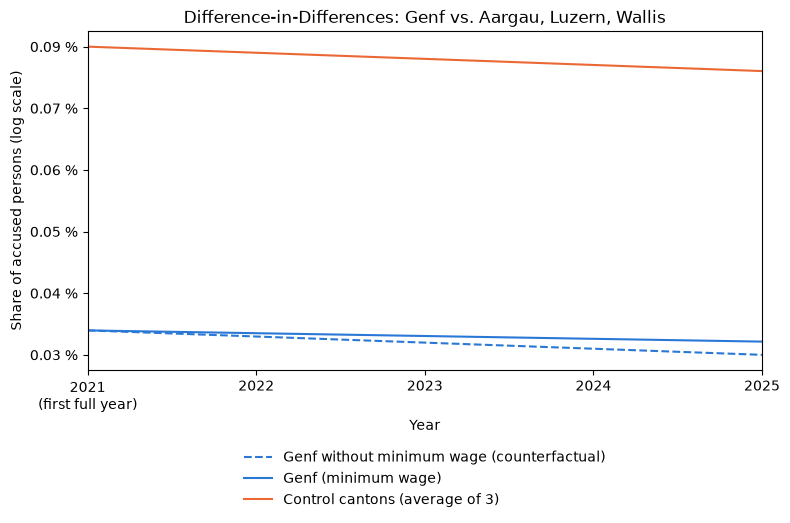

In [2]:
### DID Genf => Minimum wage in November 2020

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen
# =============================================================
MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTONE   = ["Aargau", "Luzern", "Wallis"]
ERSTES_VOLLES_JAHR = 2021          # Einführung November 2020 → erstes volles Jahr 2021

# =============================================================
# 2. Daten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)
d["After"] = (d["Year"] >= ERSTES_VOLLES_JAHR).astype(int)

# =============================================================
# 3. Regression (HC1, weil nur wenige Kantone)
# =============================================================
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"],
    "β3 (log)": [mA.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],
    "R²": [mA.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (log)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)} (erstes volles Jahr {ERSTES_VOLLES_JAHR})\n")
print(ergebnis.round({"β3 (log)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik (Schätzung in log, Achse in %)
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]
jahre = list(range(ERSTES_VOLLES_JAHR, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

# log-Werte zurück in Prozent umrechnen
treat      = np.exp([b0 + b1, b0 + b1 + b2 + b3]) * 100
kontrolle  = np.exp([b0,      b0 + b2]) * 100
kontrafakt = np.exp([b0 + b1, b0 + b1 + b2]) * 100

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

# log-skalierte Achse, beschriftet in %
plt.yscale("log")
werte = np.concatenate([treat, kontrolle, kontrafakt])
ticks = np.geomspace(werte.min(), werte.max(), 6)
plt.yticks(ticks, [f"{t:.2f} %" for t in ticks])
plt.minorticks_off()

beschriftung = [f"{ERSTES_VOLLES_JAHR}\n(first full year)"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("Share of accused persons (log scale)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

    Year  treat  kontrolle  differenz  effekt  effekt_prozent
0   2010 -8.217     -6.988     -1.228  -0.340         -28.832
1   2011 -7.778     -6.984     -0.794   0.094           9.840
2   2012 -7.511     -7.010     -0.502   0.386          47.152
3   2013 -7.499     -6.828     -0.671   0.217          24.193
4   2014 -7.786     -7.107     -0.679   0.209          23.267
5   2015 -8.285     -7.305     -0.979  -0.091          -8.696
6   2016 -8.126     -7.090     -1.036  -0.148         -13.734
7   2017 -8.310     -7.236     -1.074  -0.186         -16.934
8   2018 -8.443     -7.086     -1.358  -0.469         -37.461
9   2019 -7.905     -7.017     -0.888   0.000           0.000
10  2020 -8.081     -7.037     -1.045  -0.157         -14.493
11  2021 -8.361     -7.260     -1.101  -0.213         -19.148
12  2022 -7.851     -7.072     -0.779   0.109          11.494
13  2023 -7.555     -7.278     -0.277   0.611          84.264
14  2024 -8.053     -7.206     -0.847   0.042           4.241
15  2025

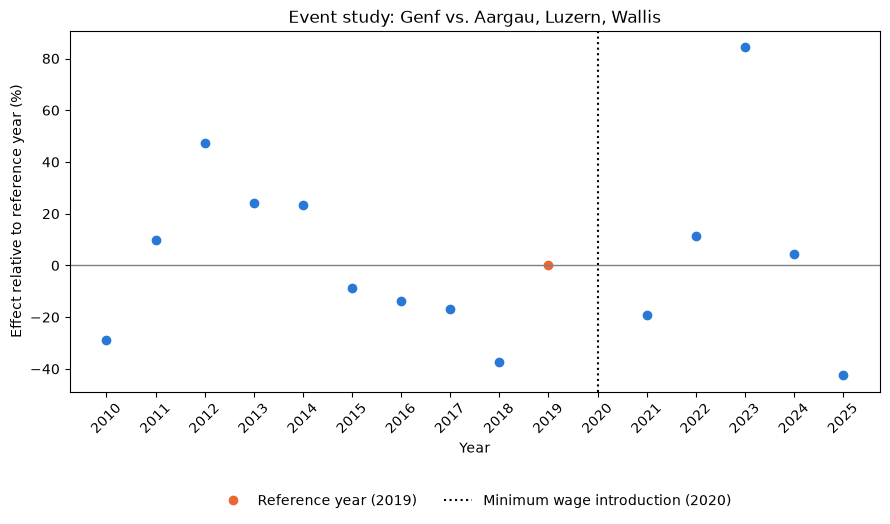

In [3]:
### Event study Genf => Minimum wage in november 2020

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Genf"
KONTROLL_KANTONE   = ["Aargau", "Luzern", "Wallis"]
EINFUEHRUNG        = 2020          # Jahr der Einführung (Genf : 2020)

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz

# Schritt 5: log-Differenz in % umrechnen
es["effekt_prozent"] = (np.exp(es["effekt"]) - 1) * 100
print(es.round(3))

# Schritt 6: plotten
punkte         = es[(es["Year"] != EINFUEHRUNG) & (es["Year"] != EINFUEHRUNG - 1)]
referenz_punkt = es[es["Year"] == EINFUEHRUNG - 1]

plt.figure(figsize=(9, 5.5))
plt.plot(punkte["Year"], punkte["effekt_prozent"], "o", color="#2a78d6")
plt.plot(referenz_punkt["Year"], referenz_punkt["effekt_prozent"], "o", color="#eb6834",
         label=f"Reference year ({EINFUEHRUNG - 1})")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(EINFUEHRUNG, color="black", linestyle=":",
            label=f"Minimum wage introduction ({EINFUEHRUNG})")
plt.xticks(es["Year"], rotation=45)
plt.xlabel("Year")
plt.ylabel("Effect relative to reference year (%)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, ncol=2)
plt.tight_layout()
plt.show()

DiD: Basel-Stadt vs. Aargau, Bern, Solothurn, St. Gallen, Thurgau (erstes volles Jahr 2023)

Modell  β3 (log)  Std.-Fehler  p-Wert    R²  Effekt in %
   DiD    -0.582        0.142 0.00004 0.425        -44.1


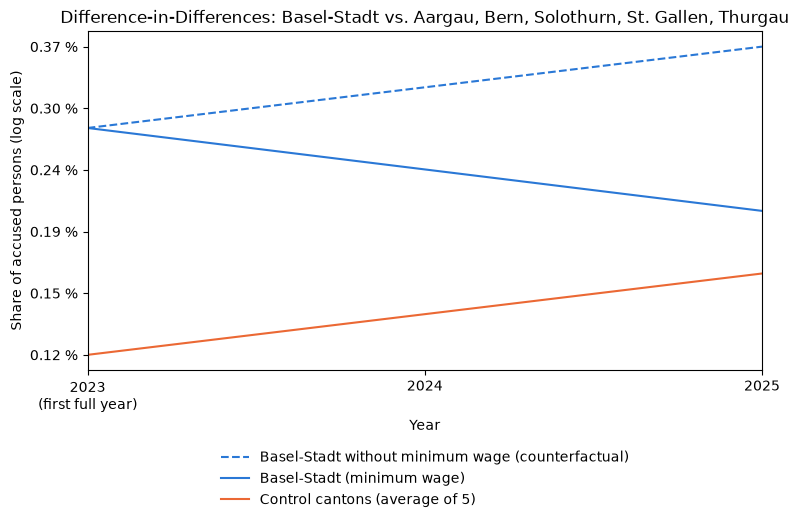

In [4]:
### Basel Stadt => Minimum wage in july 2022

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# =============================================================
# 1. Einstellungen
# =============================================================
MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTONE   = ["Aargau", "Bern", "Solothurn", "St. Gallen", "Thurgau"]
ERSTES_VOLLES_JAHR = 2023          # Einführung Juli 2022 → erstes volles Jahr 2023
# =============================================================
# 2. Daten
# =============================================================
df = pd.read_csv("Crime_Pop_clean_copy2.csv")
d = df[df["Canton"].isin([MINDESTLOHN_KANTON] + KONTROLL_KANTONE)].copy()
d["log_rate"] = np.log(d["Number of Accused Persons"] / d["Resident Population"])
d["Treat"] = (d["Canton"] == MINDESTLOHN_KANTON).astype(int)
d["After"] = (d["Year"] >= ERSTES_VOLLES_JAHR).astype(int)

# =============================================================
# 3. Regression (HC1, weil nur wenige Kantone)
# =============================================================
mA = smf.ols("log_rate ~ Treat + After + Treat:After", data=d).fit(cov_type="HC1")

# =============================================================
# 4. Ergebnisse
# =============================================================
ergebnis = pd.DataFrame({
    "Modell": ["DiD"],
    "β3 (log)": [mA.params["Treat:After"]],
    "Std.-Fehler": [mA.bse["Treat:After"]],
    "p-Wert": [mA.pvalues["Treat:After"]],
    "R²": [mA.rsquared],
})
ergebnis["Effekt in %"] = (np.exp(ergebnis["β3 (log)"]) - 1) * 100

print(f"DiD: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)} (erstes volles Jahr {ERSTES_VOLLES_JAHR})\n")
print(ergebnis.round({"β3 (log)": 3, "Std.-Fehler": 3, "p-Wert": 5, "R²": 3, "Effekt in %": 1})
      .to_string(index=False))

# =============================================================
# 5. Grafik (Schätzung in log, Achse in %)
# =============================================================
b0, b1, b2, b3 = mA.params[["Intercept", "Treat", "After", "Treat:After"]]
jahre = list(range(ERSTES_VOLLES_JAHR, d["Year"].max() + 1))
x = [jahre[0], jahre[-1]]

# log-Werte zurück in Prozent umrechnen
treat      = np.exp([b0 + b1, b0 + b1 + b2 + b3]) * 100
kontrolle  = np.exp([b0,      b0 + b2]) * 100
kontrafakt = np.exp([b0 + b1, b0 + b1 + b2]) * 100

plt.figure(figsize=(8, 5.5))
plt.plot(x, kontrafakt, color="#2a78d6", linestyle="--",
         label=f"{MINDESTLOHN_KANTON} without minimum wage (counterfactual)")
plt.plot(x, treat, color="#2a78d6", label=f"{MINDESTLOHN_KANTON} (minimum wage)")
plt.plot(x, kontrolle, color="#eb6834", label=f"Control cantons (average of {len(KONTROLL_KANTONE)})")

# log-skalierte Achse, beschriftet in %
plt.yscale("log")
werte = np.concatenate([treat, kontrolle, kontrafakt])
ticks = np.geomspace(werte.min(), werte.max(), 6)
plt.yticks(ticks, [f"{t:.2f} %" for t in ticks])
plt.minorticks_off()

beschriftung = [f"{ERSTES_VOLLES_JAHR}\n(first full year)"] + [str(j) for j in jahre[1:]]
plt.xticks(jahre, beschriftung)
plt.xlim(jahre[0], jahre[-1])
plt.xlabel("Year")
plt.ylabel("Share of accused persons (log scale)")
plt.title(f"Difference-in-Differences: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

    Year  treat  kontrolle  differenz  effekt  effekt_prozent
0   2010 -5.652     -6.650      0.998   0.194          21.434
1   2011 -5.822     -6.793      0.971   0.167          18.140
2   2012 -5.760     -6.729      0.969   0.165          17.901
3   2013 -6.270     -6.796      0.526  -0.278         -24.234
4   2014 -6.011     -6.739      0.728  -0.076          -7.293
5   2015 -5.959     -6.795      0.835   0.031           3.167
6   2016 -6.104     -6.749      0.644  -0.159         -14.733
7   2017 -5.879     -6.910      1.031   0.227          25.500
8   2018 -5.945     -6.784      0.839   0.035           3.568
9   2019 -5.853     -6.592      0.739  -0.064          -6.246
10  2020 -5.937     -6.595      0.658  -0.146         -13.592
11  2021 -5.667     -6.470      0.804   0.000           0.000
12  2022 -5.769     -6.473      0.704  -0.100          -9.476
13  2023 -5.979     -6.477      0.498  -0.306         -26.368
14  2024 -6.164     -6.360      0.196  -0.608         -45.544
15  2025

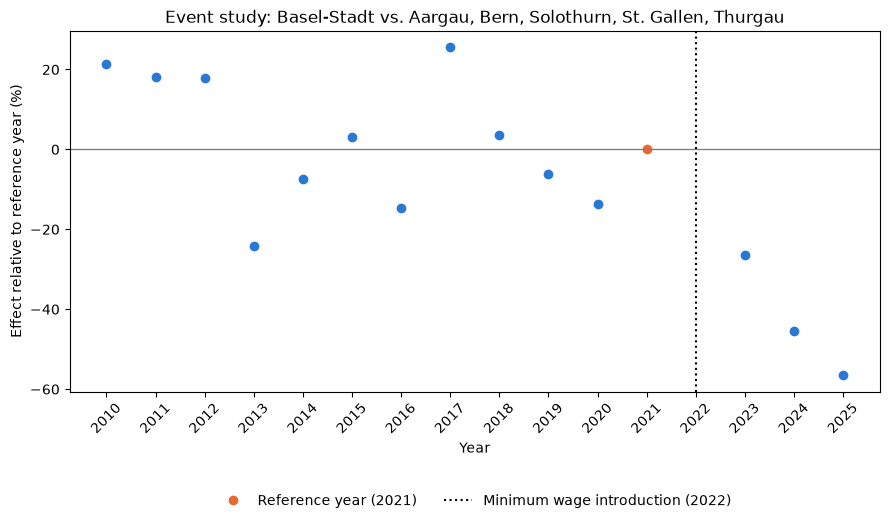

In [5]:
### Event study Basel Stadt => Minimum wage in july 2022

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MINDESTLOHN_KANTON = "Basel-Stadt"
KONTROLL_KANTONE   = ["Aargau", "Bern", "Solothurn", "St. Gallen", "Thurgau"]
EINFUEHRUNG        = 2022          # Jahr der Einführung (Basel stadt: 2022)

df = pd.read_csv("Crime_Pop_clean_copy2.csv")
df["log_rate"] = np.log(df["Number of Accused Persons"] / df["Resident Population"])

# Schritt 1: log_rate des Mindestlohn-Kantons pro Jahr
treat = df[df["Canton"] == MINDESTLOHN_KANTON][["Year", "log_rate"]]
treat = treat.rename(columns={"log_rate": "treat"})

# Schritt 2: Durchschnitt der Kontrollkantone pro Jahr
kontrolle = (df[df["Canton"].isin(KONTROLL_KANTONE)]
             .groupby("Year", as_index=False)["log_rate"].mean()
             .rename(columns={"log_rate": "kontrolle"}))

# Schritt 3: zusammenfügen und Differenz pro Jahr
es = treat.merge(kontrolle, on="Year")
es["differenz"] = es["treat"] - es["kontrolle"]

# Schritt 4: Differenz im Jahr vor der Einführung abziehen (Referenzjahr = 0)
referenz = es.loc[es["Year"] == EINFUEHRUNG - 1, "differenz"].iloc[0]
es["effekt"] = es["differenz"] - referenz

# Schritt 5: log-Differenz in % umrechnen
es["effekt_prozent"] = (np.exp(es["effekt"]) - 1) * 100
print(es.round(3))

# Schritt 6: plotten
punkte         = es[(es["Year"] != EINFUEHRUNG) & (es["Year"] != EINFUEHRUNG - 1)]
referenz_punkt = es[es["Year"] == EINFUEHRUNG - 1]

plt.figure(figsize=(9, 5.5))
plt.plot(punkte["Year"], punkte["effekt_prozent"], "o", color="#2a78d6")
plt.plot(referenz_punkt["Year"], referenz_punkt["effekt_prozent"], "o", color="#eb6834",
         label=f"Reference year ({EINFUEHRUNG - 1})")
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(EINFUEHRUNG, color="black", linestyle=":",
            label=f"Minimum wage introduction ({EINFUEHRUNG})")
plt.xticks(es["Year"], rotation=45)
plt.xlabel("Year")
plt.ylabel("Effect relative to reference year (%)")
plt.title(f"Event study: {MINDESTLOHN_KANTON} vs. {', '.join(KONTROLL_KANTONE)}")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, ncol=2)
plt.tight_layout()
plt.show()